# IT2011 – Company Bankruptcy Prediction

**Group ID:** 2026-Y2-S1-MET-16

**Student Name:** Parindya K. P.

**IT Number:** IT25102104

**Machine Learning Model:** SVM (Support Vector Machine) (assigned in the final group report; not implemented in this notebook)

**Notebook Content:** Outlier Removal using IQR (data preprocessing)

### Overview

This notebook loads the Company Bankruptcy Prediction dataset and applies the preceding cleaning steps. The step owned by this student removes outliers using the 1.5 × IQR rule on the five features most correlated with the target, applied to non-bankrupt rows only so that all bankrupt cases are kept. No machine learning model is trained in this notebook.

## Import Libraries

In [ ]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler   # for Technique 4

sns.set(color_codes=True)
%matplotlib inline

# show every column instead of truncating with "..."
pd.set_option('display.max_columns', None)

# detects whether this is running in Colab or local Jupyter
IN_COLAB = 'google.colab' in sys.modules


## Data Loading

Loads `data.csv` (upload dialog in Colab, local file in Jupyter).

In [ ]:
if IN_COLAB:
    from google.colab import files
    # opens the upload dialog
    uploaded = files.upload()
    filename = list(uploaded.keys())[0]
else:
  # expects data.csv in the same folder (e.g. data/raw/data.csv)
    filename = "data.csv"

df = pd.read_csv(filename)
df.shape


Saving data.csv to data.csv


(6819, 96)

In [ ]:
print("Shape:", df.shape)
print(df['Bankrupt?'].value_counts())

# a genuine mix of both classes, not just the first 5 rows
sample_mix = pd.concat([
    df[df['Bankrupt?'] == 0].sample(3, random_state=42),
    df[df['Bankrupt?'] == 1].sample(3, random_state=42)
]).sort_index()
display(sample_mix)

Shape: (6819, 96)
Bankrupt?
0    6599
1     220
Name: count, dtype: int64


,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,Continuous interest rate (after tax),Operating Expense Rate,Research and development expense rate,Cash flow rate,Interest-bearing debt interest rate,Tax rate (A),Net Value Per Share (B),Net Value Per Share (A),Net Value Per Share (C),Persistent EPS in the Last Four Seasons,Cash Flow Per Share,Revenue Per Share (Yuan ¥),Operating Profit Per Share (Yuan ¥),Per Share Net profit before tax (Yuan ¥),Realized Sales Gross Profit Growth Rate,Operating Profit Growth Rate,After-tax Net Profit Growth Rate,Regular Net Profit Growth Rate,Continuous Net Profit Growth Rate,Total Asset Growth Rate,Net Value Growth Rate,Total Asset Return Growth Rate Ratio,Cash Reinvestment %,Current Ratio,Quick Ratio,Interest Expense Ratio,Total debt/Total net worth,Debt ratio %,Net worth/Assets,Long-term fund suitability ratio (A),Borrowing dependency,Contingent liabilities/Net worth,Operating profit/Paid-in capital,Net profit before tax/Paid-in capital,Inventory and accounts receivable/Net value,Total Asset Turnover,Accounts Receivable Turnover,Average Collection Days,Inventory Turnover Rate (times),Fixed Assets Turnover Frequency,Net Worth Turnover Rate (times),Revenue per person,Operating profit per person,Allocation rate per person,Working Capital to Total Assets,Quick Assets/Total Assets,Current Assets/Total Assets,Cash/Total Assets,Quick Assets/Current Liability,Cash/Current Liability,Current Liability to Assets,Operating Funds to Liability,Inventory/Working Capital,Inventory/Current Liability,Current Liabilities/Liability,Working Capital/Equity,Current Liabilities/Equity,Long-term Liability to Current Assets,Retained Earnings to Total Assets,Total income/Total expense,Total expense/Assets,Current Asset Turnover Rate,Quick Asset Turnover Rate,Working capitcal Turnover Rate,Cash Turnover Rate,Cash Flow to Sales,Fixed Assets to Assets,Current Liability to Liability,Current Liability to Equity,Equity to Long-term Liability,Cash Flow to Total Assets,Cash Flow to Liability,CFO to Assets,Cash Flow to Equity,Current Liability to Current Assets,Liability-Assets Flag,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
1865,1,0.207722,0.236862,0.237272,0.599360,0.599360,0.998834,0.796646,0.808621,0.302508,0.780830,0.000227,3.960000e+09,0.457840,0.000161,0.000000,0.126838,0.126838,0.126838,0.101825,0.302292,0.034439,0.074912,0.076147,0.022064,0.847459,0.681503,0.681503,0.216713,5.140000e+09,2.041768e-04,0.259957,0.206484,0.003705,0.001893,0.630576,0.508690,0.292590,0.707410,0.004729,0.734611,0.042676,0.075325,0.079888,0.707445,0.154423,0.001000,0.006326,7.170000e+09,2.307318e-04,0.079194,0.021439,0.382895,0.011735,0.653732,0.384783,0.627396,0.033725,0.002209,0.000591,0.302765,0.330028,0.276608,0.004219,0.998102,0.507149,0.775890,0.000000,0.871284,0.002024,0.157324,1.417064e-04,8.750000e+09,0.593855,2.160000e+09,0.671567,0.372397,0.998102,0.775890,0.110933,0.631706,0.458283,0.465453,0.255684,0.075495,0,0.605902,0.001827,0.623288,0.599360,0.344652,0.643692,0.026781,0.565108,1,0.010494
2100,1,0.489933,0.562854,0.537770,0.604138,0.604138,0.999018,0.797612,0.809480,0.303810,0.781701,0.000120,3.060000e+08,0.468037,0.000911,0.206600,0.179596,0.179596,0.179596,0.223882,0.334618,0.015639,0.099340,0.182948,0.022010,0.847959,0.689349,0.689349,0.217581,5.890000e+09,4.786001e-04,0.263875,0.408945,0.010559,0.004129,0.632611,0.008998,0.146869,0.853131,0.008331,0.377607,0.005366,0.099362,0.182007,0.413828,0.058471,0.000284,0.022318,1.220000e+0

## Outlier Removal using IQR

*Section owner: Parindya K. P. (IT25102104)*

Applying the IQR rule to every column would remove most rows and risk deleting the rare bankrupt cases. It is therefore applied only to the five features most correlated with the target, and only to non-bankrupt rows.

In [ ]:
# correlate every feature with the target, then take the 5 most correlated
corr_target = df.corr(numeric_only=True)['Bankrupt?'].drop('Bankrupt?').abs().sort_values(ascending=False)
numeric_cols = corr_target.head(5).index
list(numeric_cols)


['Net Income to Total Assets',
 'ROA(A) before interest and % after tax',
 'ROA(B) before interest and depreciation after tax',
 'ROA(C) before interest and depreciation before interest',
 'Net worth/Assets']

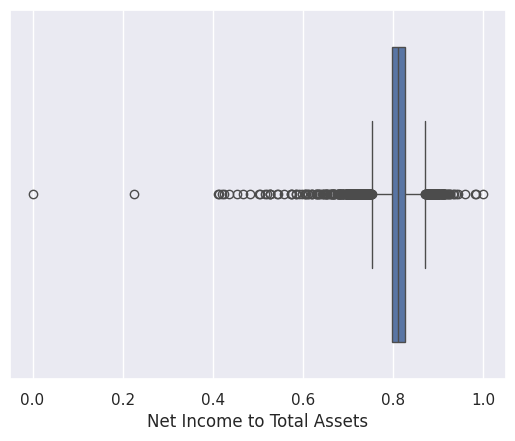

In [ ]:
# visualize outliers for the top feature
sns.boxplot(x=df['Net Income to Total Assets'])
plt.show()


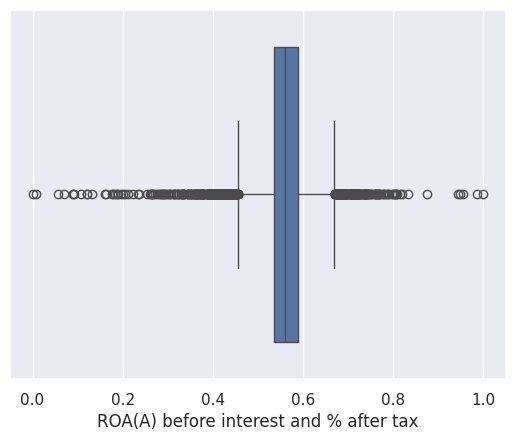

In [ ]:
# visualize outliers for the 2nd top feature
sns.boxplot(x=df["ROA(A) before interest and % after tax"])
plt.show()


In [ ]:
# not-bankrupt rows — outliers are removed only from here
majority_df = df[df['Bankrupt?'] == 0]
# bankrupt rows — kept untouched
minority_df = df[df['Bankrupt?'] == 1]

Q1 = majority_df[numeric_cols].quantile(0.25)
Q3 = majority_df[numeric_cols].quantile(0.75)
IQR = Q3 - Q1

# keep rows that fall inside the IQR bounds on every selected column
condition = ~((majority_df[numeric_cols] < (Q1 - 1.5 * IQR)) | (majority_df[numeric_cols] > (Q3 + 1.5 * IQR))).any(axis=1)
majority_cleaned = majority_df[condition]

# rejoin cleaned majority + untouched minority
df_cleaned = pd.concat([majority_cleaned, minority_df]).sort_index()
print(df.shape)
print(df_cleaned.shape)


(6819, 95)
(6198, 95)


In [ ]:
df = df_cleaned
(df['Bankrupt?'] == 1).sum()   # confirm all bankrupt rows are still present


np.int64(220)

All 220 bankrupt rows are retained; only extreme non-bankrupt rows were removed (6,819 → 6,198 rows).